# LA 03b — Preserve structural take-profit, mirror stop distance (1:1 RR)

**Requested hypothesis:** hold the **same original A03 entry and structural take-profit** (session VWAP if its original A03 2R displacement criterion is met; otherwise opposite previous-day extreme). **Move only the initial stop** to the other side of entry at exactly the same price distance. For a long, stop = `2*entry_print - target`; for a short, identical formula. The target is **not shortened**. Use the same 452 A02/A02b candidates and the same trade-print order, 240m timeout, fee and adverse-fill assumptions as A03.

Only **fixed 1:1 exits** are relevant: the previous +1R break-even activation occurs at the 1R take-profit, so its one-minute swing trailing cannot engage before target without changing a second rule. A03b verifies policy outcome equivalence. This comparison was requested **after** inspecting A03 outcomes and is exploratory, *not* a prospective or independent strategy validation.

The figures below are **historical virtual cumulative P&L** under **USDT 10,000 fixed notional per separate candidate** and show only the *paired completed trades* across A03 and A03b, each realized at its respective exit time. They are **not investable equity curves**: overlapping trade exposure, capital/leverage constraints, mark-to-market unrealized P&L and funding are not modeled. The `.png` output files are saved under `03b/` for review directly in GitHub.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

REPO = Path.cwd().resolve()
while not (REPO / "src" / "data_engineering").is_dir():
    if REPO == REPO.parent:
        raise RuntimeError("Start Jupyter inside deribit-market-data repository")
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.data_engineering.modeling.liquidity_absorption_stage_a import binance_root
from src.data_engineering.modeling.liquidity_absorption_stage_a03b import VERSION, run_a03b
assert VERSION == "LA-A03b-0.1.0", "Pull latest repo and restart kernel"
DATA_ROOT = binance_root(REPO)
OUT = REPO / "notebooks" / "Liquidity_Absorption" / "03b"
print("Version:", VERSION, "| Local Binance root:", DATA_ROOT)
print("Same A03 structural TP, mirrored 1:1 initial stop, fixed exits, historical gross/net curves")

Version: LA-A03b-0.1.0 | Local Binance root: D:\MarketData\Binance
Same A03 structural TP, mirrored 1:1 initial stop, fixed exits, historical gross/net curves


In [2]:
result = run_a03b(REPO, DATA_ROOT, OUT)
print("Completed:", result["version"], "| Events:", result["source_events"])
print("Paired completed trades:", result["paired_closed_events"])
print("Missing tape files:", result["print_tape"]["missing_trade_day_files"])
display(pd.DataFrame(result["coverage"]))

Completed: LA-A03b-0.1.0 | Events: 452
Paired completed trades: 413
Missing tape files: ['BTCUSDT:2026-10-01', 'ETHUSDT:2026-10-01']


,symbol,candidates,closed,stop,target,timeout,no_structural_target,other_no_entry,censored,gross_r_mean,net_r_mean,net_return_bp_mean,profitable_closed_share,initial_risk_bp_median,paired_closed_original_a03_fixed,original_a03_fixed_paired_net_return_bp_mean,mirrored_paired_net_return_bp_mean
0,BTCUSDT,212,195,55,51,89,16,0,1,0.002187,-0.287486,-17.713496,0.451282,69.365240,195,-13.599220,-17.713496
1,ETHUSDT,240,218,57,65,96,21,0,1,0.043039,-0.206969,-13.990027,0.472477,79.371596,218,-13.612994,-13.990027


In [3]:
trades = pd.read_csv(OUT / "03b_1to1_events.csv")
comparison = pd.read_csv(OUT / "03b_paired_comparison.csv")
print("Exit reasons (including skipped/censored):")
display(trades.groupby(["symbol", "reason"]).size().rename("events").reset_index())
print("Exactly 1:1 pre-cost geometry for entered trades:",
      trades.loc[trades.entry_print.notna(), "symmetric_1to1_before_costs"].all())
paired = comparison.loc[comparison.paired_closed]
print("Paired comparison by symbol (same underlying candidates, different exit timestamps):")
display(paired.groupby("symbol_1to1")[
    ["net_return_bp_assumed_costs_old", "net_return_bp_assumed_costs_1to1",
     "gross_return_bp_old", "gross_return_bp_1to1"]].mean())

Exit reasons (including skipped/censored):


,symbol,reason,events
0,BTCUSDT,CENSORED_TAPE_END,1
1,BTCUSDT,NO_STRUCTURAL_TARGET,16
2,BTCUSDT,STOP,55
3,BTCUSDT,TARGET,51
4,BTCUSDT,TIMEOUT,89
5,ETHUSDT,CENSORED_TAPE_END,1
6,ETHUSDT,NO_STRUCTURAL_TARGET,21
7,ETHUSDT,STOP,57
8,ETHUSDT,TARGET,65
9,ETHUSDT,TIMEOUT,96


Exactly 1:1 pre-cost geometry for entered trades: True
Paired comparison by symbol (same underlying candidates, different exit timestamps):


,net_return_bp_assumed_costs_old,net_return_bp_assumed_costs_1to1,gross_return_bp_old,gross_return_bp_1to1
symbol_1to1,,,,
BTCUSDT,-13.599220,-17.713496,0.247775,-4.427225
ETHUSDT,-13.612994,-13.990027,0.259556,-0.724558


## Historical equity-curve graphs

**Blue/other line identities:** Labels are shown directly in each chart legend. These are independently closed, fixed-notional trade outcome curves, **not a sequential single-position or capital-budgeted portfolio**. *Net* uses the original 6bp/side taker-fee and adverse execution approximations; funding remains excluded. If one variant is censored because the October 1 trade file is missing, **both variants of that event are omitted from the paired graph**, but the event remains in the trade-outcome CSV with a documented reason.

03b_equity_net.png


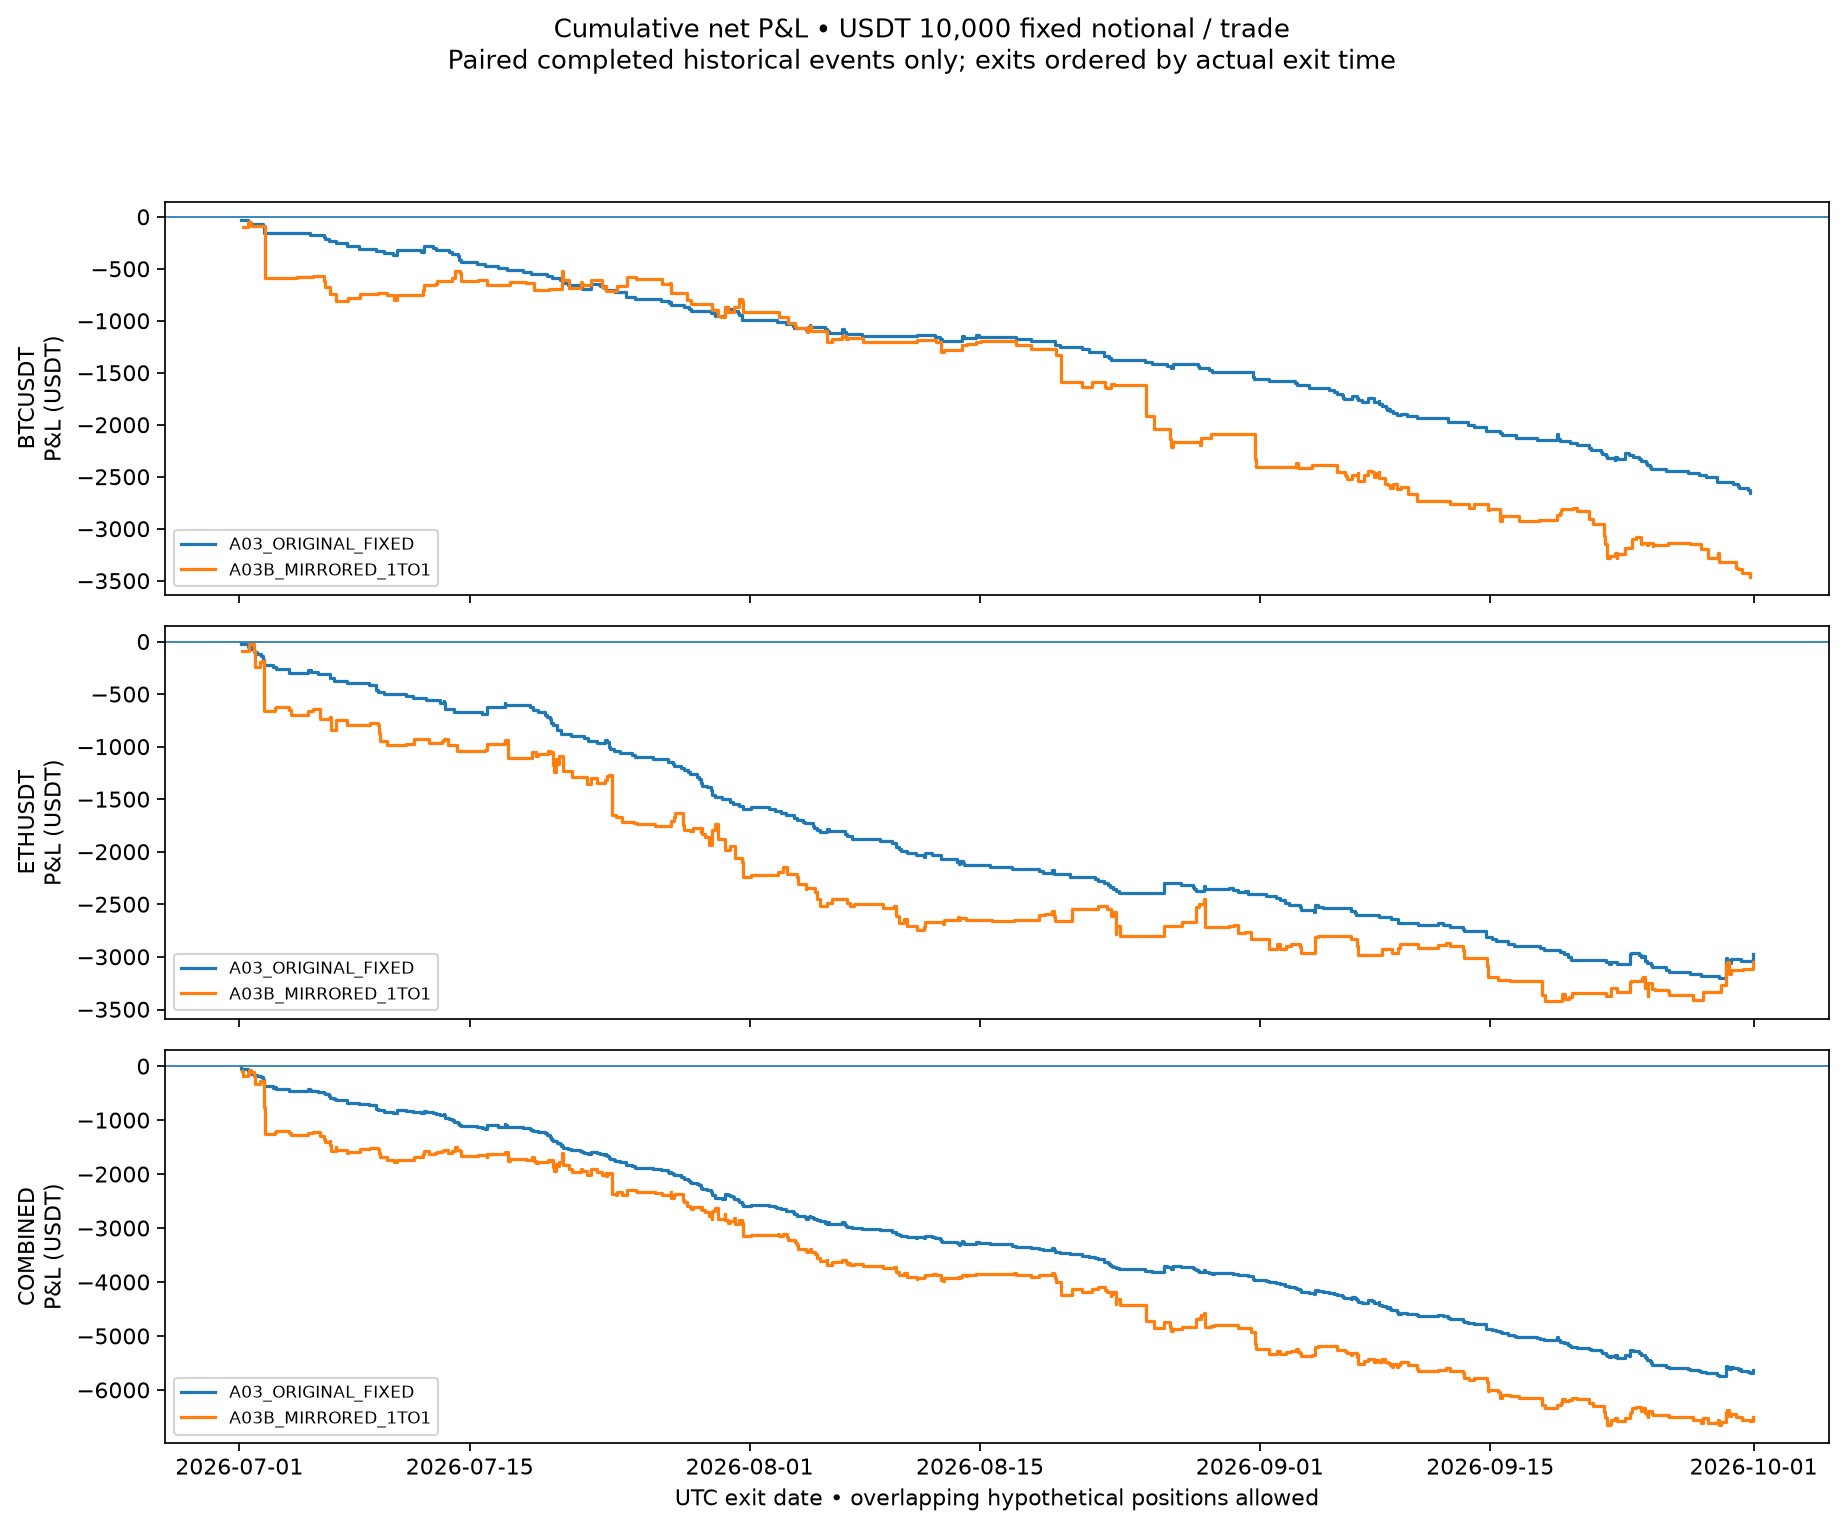

03b_equity_gross.png


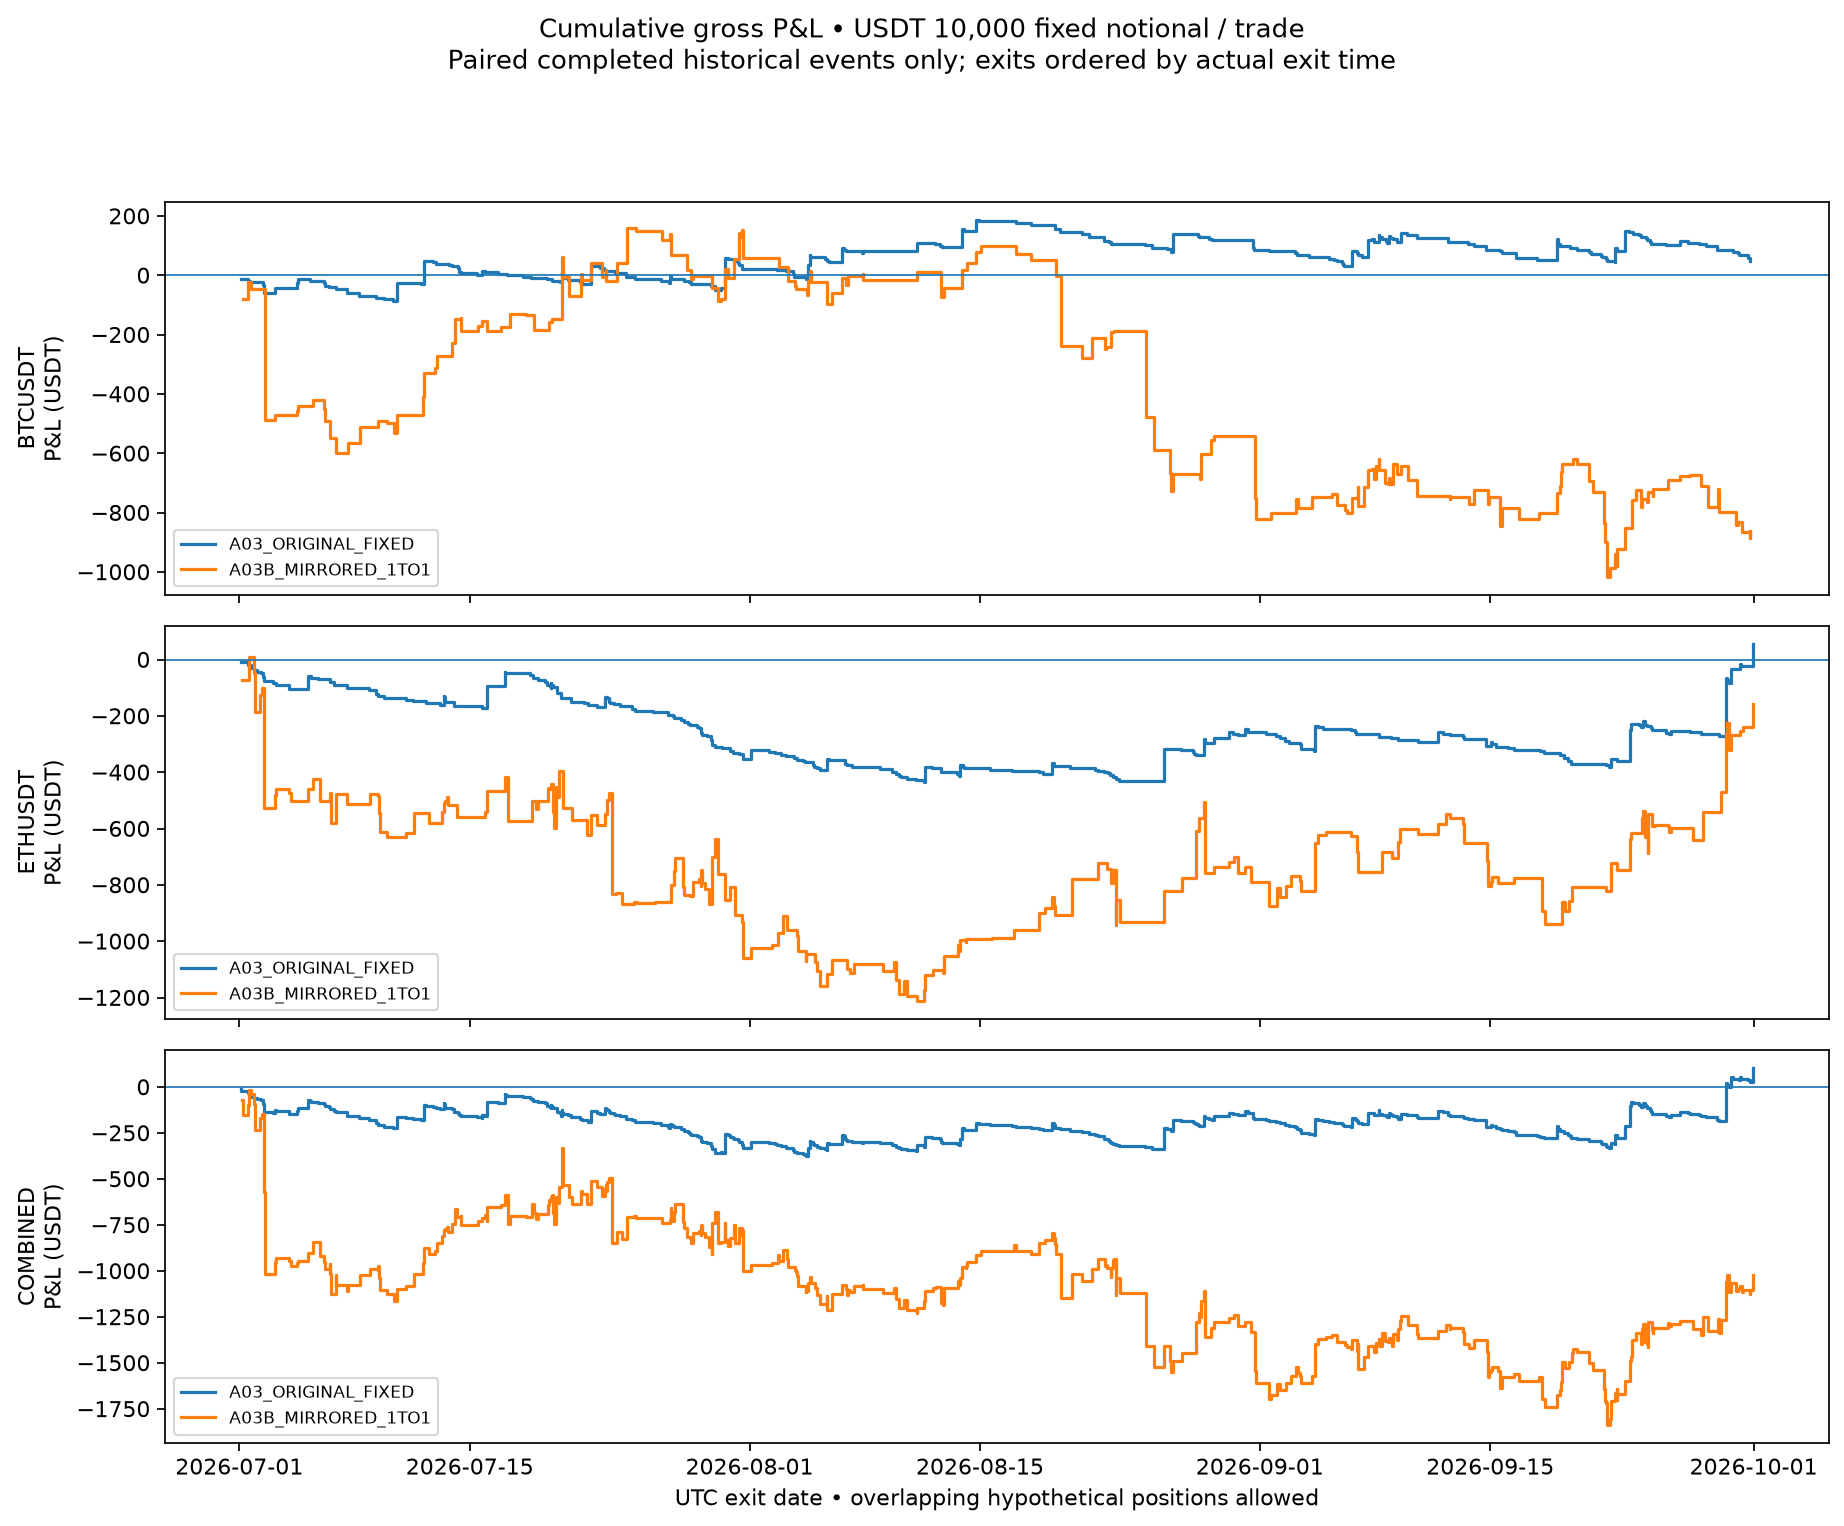

03b_1to1_r_curve.png


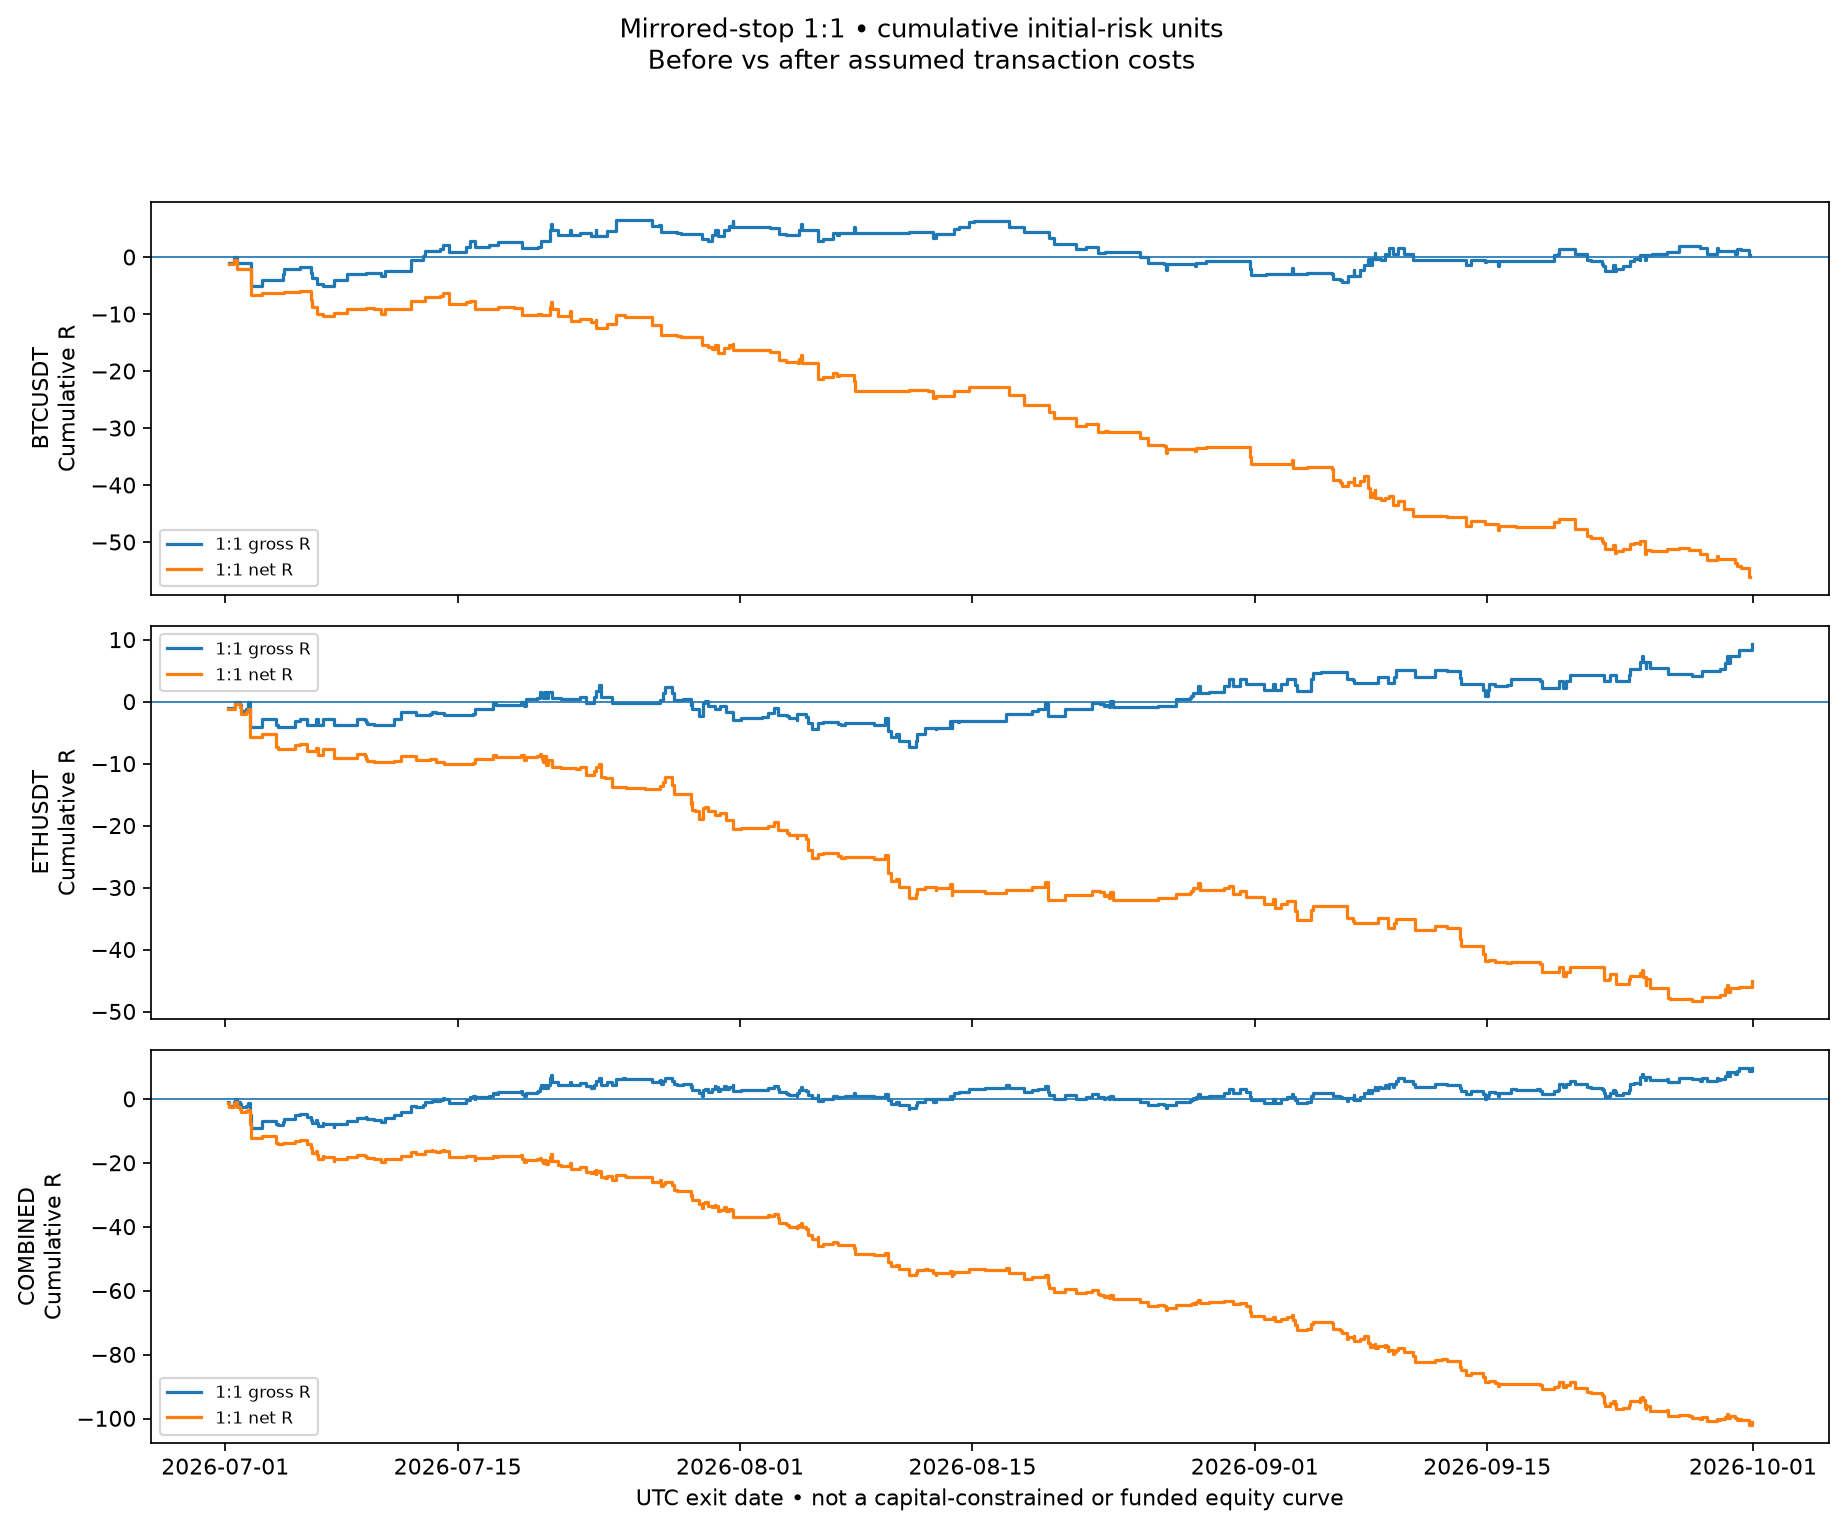

Files to push:
 - 03b_1to1_events.csv
 - 03b_1to1_r_curve.png
 - 03b_contract.json
 - 03b_coverage.csv
 - 03b_decision.json
 - 03b_equity_gross.png
 - 03b_equity_net.png
 - 03b_equity_paths.csv
 - 03b_paired_comparison.csv


In [4]:
for image_file in ("03b_equity_net.png", "03b_equity_gross.png", "03b_1to1_r_curve.png"):
    picture = OUT / image_file
    if picture.exists():
        print(image_file)
        display(Image(filename=str(picture)))
    else:
        print("Graph not created, probably no paired completed trades:", image_file)

print("Files to push:")
for f in sorted(OUT.glob("03b_*")):
    print(" -", f.name)

## Interpretation controls

- A03 originally set the initial stop just outside its 2bp zone and then chose session VWAP if sufficiently displaced; **A03b retains exactly that originally selected TP** rather than recomputing it against the newly widened risk, which would change the signal's target.
- For each entered trade, **uncosted target/initial-risk distance is exactly 1:1 at the initial print**. A stop-market gap can lose more than -1R; a 240-minute timeout may close anywhere; transaction fees and assumed slippage change net R. Trade prices are NOT guaranteed executable bid/ask quotes.
- A03b mirrors unrounded continuous stop prices to preserve strict geometric equality. This is a research idealization, not a validated exchange tick-size or stop-order implementation.
- The A03 BE trigger was +1 initial R. With target itself at +1R, BE/trailing cannot alter a trade before it reaches its TP; **testing a different BE trigger would be a separate strategy change**.
- Prior A03's missing Oct 1 BTC/ETH trade tapes may censor *more* positions under the wider initial stop. Never assign censored trades manufactured exits, and inspect counts before making comparisons.
- **No statistical-significance or live-trading claim.** These July–September 2026 data are previously inspected exploratory history. Results are after assumed transaction costs **but before funding**.

Commit the executed notebook and **all generated CSV, JSON, and PNG files** under `notebooks/Liquidity_Absorption/03b/`, then request review.